## 1. Shared Data Preparation

All Milestone 2 models use the same training, validation, and test splits.

The shared `load_prepared_splits()` function replaces the previous
manual HC3 cleaning and question-level splitting code.

In [10]:
from pathlib import Path
import sys
import time
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

# Find the root of our GitHub repository.
# This lets the notebook import code stored in src/spotbot.
for candidate in [Path.cwd(), Path.cwd().parent]:
    if (candidate / "src" / "spotbot").is_dir():
        REPO_ROOT = candidate.resolve()
        break
else:
    raise RuntimeError("Could not find the Chewy repository.")

sys.path.insert(0, str(REPO_ROOT / "src"))

# Import Aryaman's shared preparation function.
from spotbot.prepared import load_prepared_splits

## 2. Load Shared Data
Load the team's standardized training, validation, and test splits.

In [11]:
# Use the local HC3 CSV if one exists.
# Otherwise, let the shared loader use its configured source.
data_path = REPO_ROOT / "data" / "hc3_all.csv"

train_df, val_df, test_df = load_prepared_splits(
    data_path if data_path.exists() else None
)

# Check that the shared datasets contain the necessary columns.
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"{name}: {df.shape}")
    print(df["label"].value_counts())
    assert {"text", "label"}.issubset(df.columns)
    assert df["text"].notna().all()
    assert df["label"].isin([0, 1]).all()

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'Hello-SimpleAI/HC3' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Train: (65401, 8)
label
0    44473
1    20928
Name: count, dtype: int64
Validation: (8218, 8)
label
0    5587
1    2631
Name: count, dtype: int64
Test: (8151, 8)
label
0    5536
1    2615
Name: count, dtype: int64


## 3. TF-IDF Feature Extraction
Convert text responses into numerical features using word unigrams and bigrams.

In [12]:
# Convert answers into numerical features.
# Fit the vocabulary on training data only to prevent leakage.
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train = tfidf.fit_transform(train_df["text"])
X_val = tfidf.transform(val_df["text"])

y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

Training features: (65401, 50000)
Validation features: (8218, 50000)


## 4. Dimensionality Reduction
Reduce TF-IDF features to 100 dimensions using TruncatedSVD.

In [13]:
start = time.perf_counter()

# Reduce the 50,000 TF-IDF features to 100 dense components.
svd = TruncatedSVD(
    n_components=100,
    algorithm="arpack",
    random_state=RANDOM_STATE
)

X_train_reduced = svd.fit_transform(X_train)
X_val_reduced = svd.transform(X_val)

# Check that SVD produced valid numerical features.
assert np.isfinite(X_train_reduced).all()
assert np.isfinite(X_val_reduced).all()

print("Reduced training shape:", X_train_reduced.shape)
print("Reduced validation shape:", X_val_reduced.shape)

print(
    "Explained variance:",
    svd.explained_variance_ratio_.sum()
)

print(f"SVD runtime: {time.perf_counter() - start:.2f} seconds")

Reduced training shape: (65401, 100)
Reduced validation shape: (8218, 100)
Explained variance: 0.07640421401499722
SVD runtime: 19.14 seconds


## 5. Baseline Gradient Boosting
Train an initial Gradient Boosting classifier and evaluate its validation performance.

In [14]:
start = time.perf_counter()

# Initial model used as a baseline for tuning.
baseline = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    early_stopping=False,
    random_state=RANDOM_STATE
)

baseline.fit(X_train_reduced, y_train)

baseline_pred = baseline.predict(X_val_reduced)

print(f"Training time: {time.perf_counter() - start:.2f} seconds")

print(
    "Baseline Validation Macro-F1:",
    f1_score(y_val, baseline_pred, average="macro")
)

print(classification_report(
    y_val,
    baseline_pred,
    labels=[0, 1],
    target_names=["Human", "AI"]
))

Training time: 3.35 seconds
Baseline Validation Macro-F1: 0.9615715384191093
              precision    recall  f1-score   support

       Human       0.97      0.98      0.98      5587
          AI       0.95      0.94      0.95      2631

    accuracy                           0.97      8218
   macro avg       0.96      0.96      0.96      8218
weighted avg       0.97      0.97      0.97      8218



## 6. Experiment 1: Number of Boosting Stages

Test 50, 100, and 200 boosting stages while keeping learning rate
and tree complexity constant.

Compare training and validation macro-F1 to investigate overfitting.

,max_iter,train_f1,val_f1
0,50,0.956620,0.950978
1,100,0.975116,0.961572
2,200,0.992045,0.966189


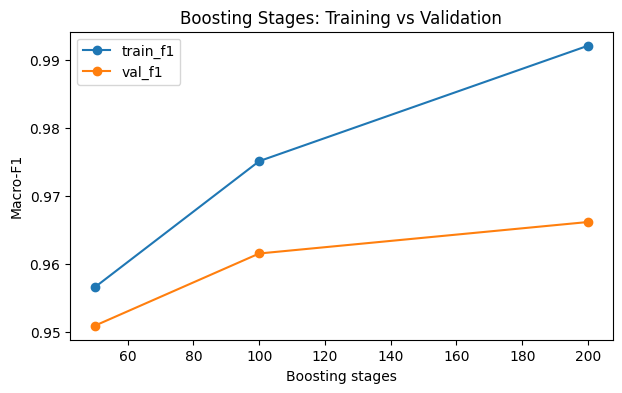

In [15]:
results = []

for n_trees in [50, 100, 200]:

    model = HistGradientBoostingClassifier(
        max_iter=n_trees,
        learning_rate=0.1,
        max_leaf_nodes=31,
        early_stopping=False,
        random_state=RANDOM_STATE
    )

    model.fit(X_train_reduced, y_train)

    # Track both training and validation performance.
    results.append({
        "max_iter": n_trees,
        "train_f1": f1_score(
            y_train, model.predict(X_train_reduced), average="macro"
        ),
        "val_f1": f1_score(
            y_val, model.predict(X_val_reduced), average="macro"
        )
    })

results_df = pd.DataFrame(results)
display(results_df)

# Visualize whether additional boosting stages improve generalization.
ax = results_df.plot(
    x="max_iter",
    y=["train_f1", "val_f1"],
    marker="o",
    figsize=(7, 4)
)

ax.set(
    xlabel="Boosting stages",
    ylabel="Macro-F1",
    title="Boosting Stages: Training vs Validation"
)

plt.show()

## 7. Experiment 2: Learning Rate and Tree Complexity

Test combinations of learning rate and maximum leaf nodes,
holding max_iter at 200.

Select the configuration with the highest validation macro-F1.

In [16]:
results_2 = []

for lr, leaves in product([0.05, 0.1], [7, 15, 31]):

    model = HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=lr,
        max_leaf_nodes=leaves,
        early_stopping=False,
        random_state=RANDOM_STATE
    )

    model.fit(X_train_reduced, y_train)

    results_2.append({
        "learning_rate": lr,
        "max_leaf_nodes": leaves,
        "train_f1": f1_score(
            y_train, model.predict(X_train_reduced), average="macro"
        ),
        "val_f1": f1_score(
            y_val, model.predict(X_val_reduced), average="macro"
        )
    })

# Sort configurations by validation performance.
results_2_df = (
    pd.DataFrame(results_2)
    .sort_values("val_f1", ascending=False)
    .reset_index(drop=True)
)

display(results_2_df)

,learning_rate,max_leaf_nodes,train_f1,val_f1
0,0.10,31,0.992045,0.966189
1,0.10,15,0.977061,0.962959
2,0.05,31,0.974836,0.961716
3,0.05,15,0.962780,0.957509
4,0.10,7,0.962699,0.957500
5,0.05,7,0.949562,0.944470


## 8. Selected Model Evaluation

Select the configuration with the best validation macro-F1.

Retrain the selected Gradient Boosting configuration using
the shared training data, then evaluate on validation data.

The test set remains untouched during model selection.

Selected hyperparameters: {'max_iter': 200, 'learning_rate': 0.1, 'max_leaf_nodes': 31, 'early_stopping': False, 'random_state': 42}
Validation Accuracy: 0.9706741299586275
Validation Macro-F1: 0.9661894269085515

Classification Report:
              precision    recall  f1-score   support

       Human       0.98      0.98      0.98      5587
          AI       0.96      0.95      0.95      2631

    accuracy                           0.97      8218
   macro avg       0.97      0.96      0.97      8218
weighted avg       0.97      0.97      0.97      8218



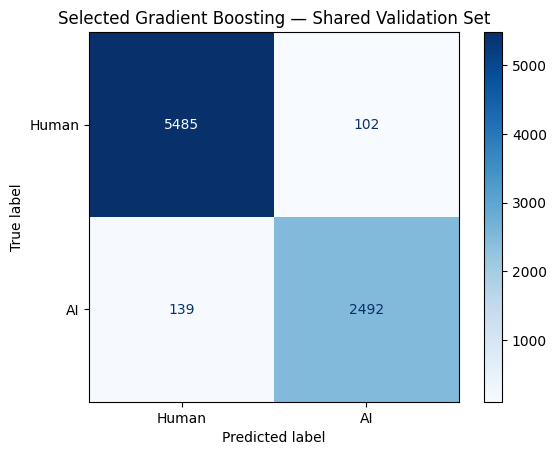

In [17]:
# Select the strongest configuration from Experiment 2.
best_row = results_2_df.iloc[0]

best_params = {
    "max_iter": 200,
    "learning_rate": float(best_row["learning_rate"]),
    "max_leaf_nodes": int(best_row["max_leaf_nodes"]),
    "early_stopping": False,
    "random_state": RANDOM_STATE
}

print("Selected hyperparameters:", best_params)

# Train the selected configuration.
best_model = HistGradientBoostingClassifier(**best_params)
best_model.fit(X_train_reduced, y_train)

# Predict on the shared validation set.
best_val_pred = best_model.predict(X_val_reduced)

print(
    "Validation Accuracy:",
    accuracy_score(y_val, best_val_pred)
)

print(
    "Validation Macro-F1:",
    f1_score(y_val, best_val_pred, average="macro")
)

print("\nClassification Report:")
print(classification_report(
    y_val,
    best_val_pred,
    labels=[0, 1],
    target_names=["Human", "AI"]
))

# Display incorrect and correct classifications.
ConfusionMatrixDisplay.from_predictions(
    y_val,
    best_val_pred,
    labels=[0, 1],
    display_labels=["Human", "AI"],
    cmap="Blues",
    values_format="d"
)

plt.title("Selected Gradient Boosting — Shared Validation Set")
plt.show()

## 9. Findings

### Baseline Performance
- Validation macro-F1: 0.9616
- Training time: 1.66 seconds
- SVD explained variance: 7.64%

### Experiment 1: Number of Boosting Stages
- Best max_iter: 200
- Highest validation macro-F1: 0.9662
- Training macro-F1: 0.9920

Increasing the number of boosting stages improved validation performance.
However, the gap between training and validation macro-F1 increased,
suggesting some overfitting.

### Experiment 2: Learning Rate and Tree Complexity
- Best learning rate: 0.1
- Best maximum leaf nodes: 31
- Highest validation macro-F1: 0.9662

The most complex tree configuration tested achieved the highest validation macro-F1.

### Selected Model
- max_iter: 200
- learning_rate: 0.1
- max_leaf_nodes: 31
- early_stopping: False
- SVD components: 100
- SVD algorithm: ARPACK

**Validation Results**
- Accuracy: 97.07%
- Macro-F1: 0.9662

### Limitations and Next Steps

- SVD retains approximately 7.64% of TF-IDF variance,
  so some useful information may be lost.
- The hyperparameter search covers a limited set of configurations.
- Compare against Linear SVM using the same shared splits.
- Reserve the test set for final model evaluation.